In [1]:
import astrolabe as ab

In [2]:
# Transcripts are streamed and stored in mdata['xenium'].uns['transcripts'] automatically.
data = ab.io.read_xenium('output-XETG00659__0076505__76505_region_1__20260403__201533', morphology_image=True)
data

C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\utils.py:362: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(msg, category, stacklevel=stacklevel)


MuData object with n_obs × n_vars = 162345 × 9872
  uns:	'spatial', 'astrolabe_schema_version', 'default_modality'
  1 modality
    xenium:	162345 × 9872
      obs:	'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'nucleus_count'
      var:	'gene_id', 'feature_type', 'genome', 'is_control_probe'
      uns:	'spatial', 'astrolabe_schema_version', 'transcripts'
      obsm:	'spatial', 'cell_boundaries', 'nucleus_boundaries'

## QC Metrics

In [3]:
# Xenium probe-type QC first: computes per-cell control probe counts and removes
# control probes from var so downstream metrics are gene-expression-only.
ab.pp.calculate_xenium_qc_metrics(data)
data['xenium'].obs[['unassigned_codeword_total', 'negative_control_probe_total',
                     'pct_any_negative_control_probes']].describe()

,unassigned_codeword_total,negative_control_probe_total,pct_any_negative_control_probes
count,162345.000000,162345.000000,161655.000000
mean,0.002187,0.004903,0.284242
std,0.046974,0.074378,1.143378
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.174368
max,2.000000,4.000000,100.000000


In [4]:
# General per-cell and per-gene QC metrics — control probes already removed.
# total_counts and n_genes_by_counts reflect gene expression only.
ab.pp.calculate_qc_metrics(data)
data['xenium'].obs.head()

,cell_area,nucleus_area,transcript_counts,control_probe_counts,control_codeword_counts,nucleus_count,unassigned_codeword_total,deprecated_codeword_total,genomic_control_probe_total,negative_control_codeword_total,...,pct_negative_control_probes,pct_any_negative_control_probes,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes
cell_id,,,,,,,,,,,,,,,,,,,,,
aaaaaeml-1,100.066254,26.055157,883,0,0,1,0.0,3.0,0.0,0.0,...,0.0,0.338600,548,6.308098,883.0,6.784457,29.784824,42.582106,60.588901,94.563986
aaaacofb-1,102.504691,62.902659,1332,0,0,1,0.0,0.0,0.0,0.0,...,0.0,0.000000,794,6.678342,1332.0,7.195187,25.675676,37.162162,52.252252,77.927928
aaaafdki-1,55.497033,41.634064,522,0,0,1,0.0,1.0,1.0,0.0,...,0.0,0.381679,381,5.945421,522.0,6.259582,33.524904,46.168582,65.325670,100.000000
aaacbmnb-1,147.435162,60.825471,1419,0,0,1,0.0,1.0,1.0,0.0,...,0.0,0.140746,817,6.706862,1419.0,7.258412,25.651868,36.645525,51.585624,77.660324
aaacbpal-1,58.116096,35.944376,402,0,0,1,0.0,2.0,0.0,0.0,...,0.0,0.495050,311,5.743003,402.0,5.998937,35.074627,47.512438,72.388060,100.000000


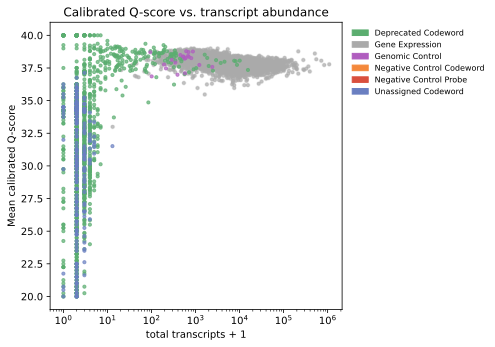

In [5]:
# Mean calibrated Q-score vs. log transcript abundance for gene expression probes.
# Uses mean_qv computed by calculate_xenium_qc_metrics and total_counts from calculate_qc_metrics.
ab.pl.gene_qv_scatter(data)

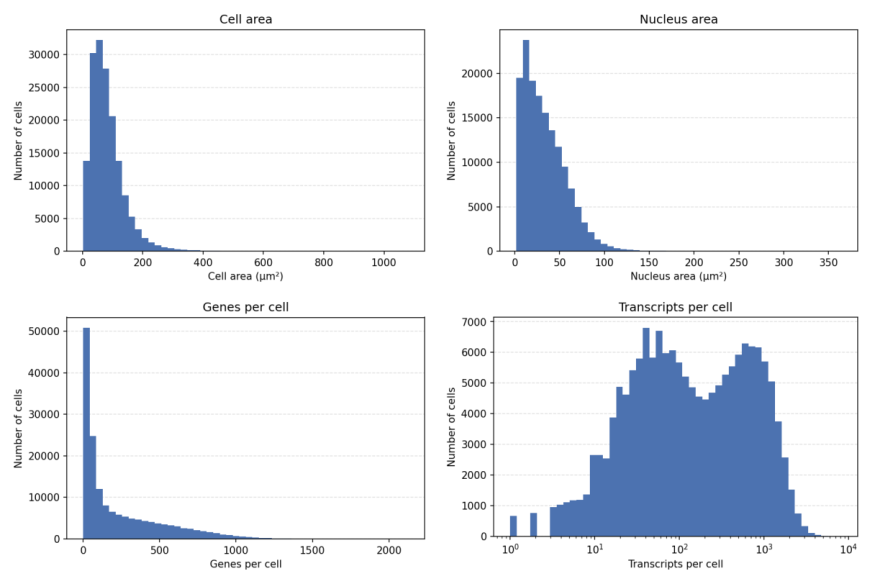

In [6]:
# Cell/nucleus area, genes per cell, and transcripts per cell.
# Pass vlines= to overlay filter thresholds (e.g. vlines=[10] for min_counts=10).
(
    ab.pl.cell_area_histogram(data)
    | ab.pl.nucleus_area_histogram(data)
) / (
    ab.pl.genes_per_cell_histogram(data)
    | ab.pl.transcripts_per_cell_histogram(data)
)

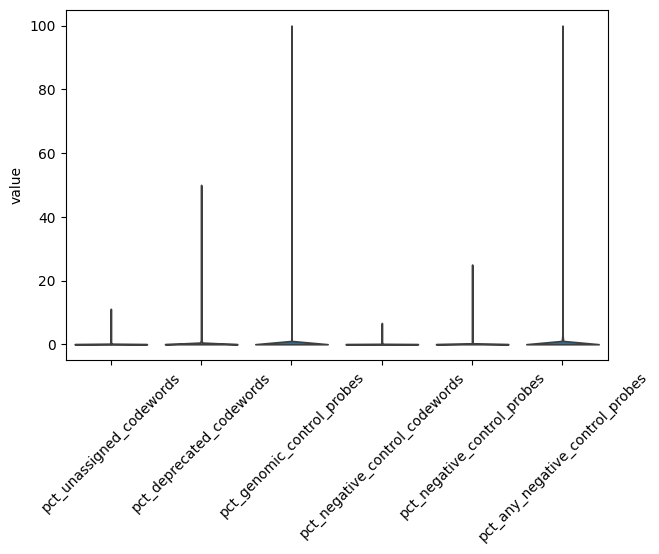

In [7]:
# Per-cell fraction of counts from each control probe category.
ab.pl.violin(
    data,
    ['pct_unassigned_codewords', 'pct_deprecated_codewords',
     'pct_genomic_control_probes', 'pct_negative_control_codewords',
     'pct_negative_control_probes', 'pct_any_negative_control_probes'],
    stripplot=False,
    rotation=45,
)

## Spatial Plots

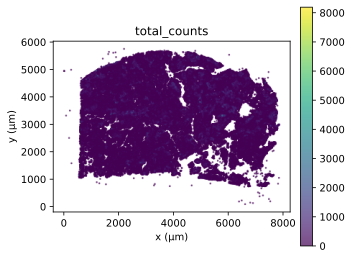

In [8]:
# Total transcript counts per cell — reveals tissue structure and cell density gradients.
ab.pl.points(data, color='total_counts')

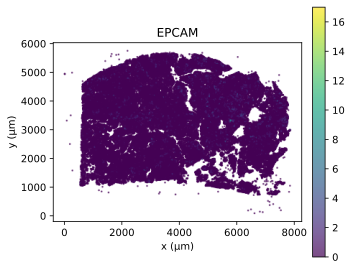

In [9]:
# Single marker gene — spatial expression pattern.
ab.pl.points(data, color='EPCAM')

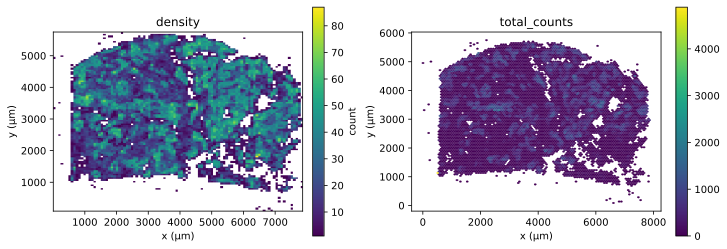

In [10]:
# Rasterised cell density — faster than points for large datasets.
ab.pl.raster(data) | ab.pl.raster(data, bin_shape='hex', color='total_counts')

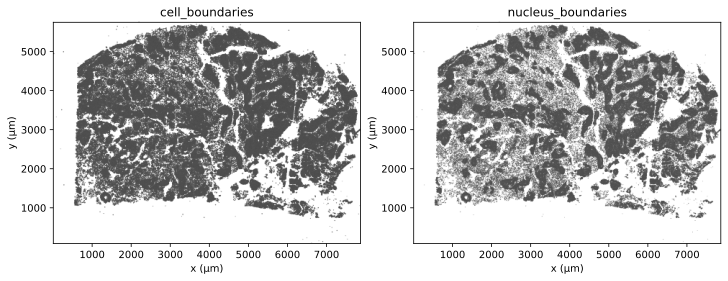

In [11]:
ab.pl.boundaries(data) | ab.pl.boundaries(data, boundaries_key='nucleus_boundaries')

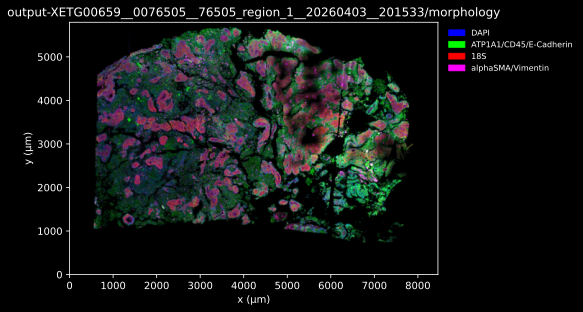

In [12]:
ab.pl.image(data)

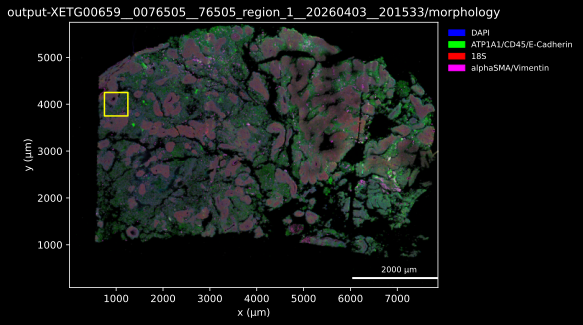

In [13]:
ab.pl.image(data, scale_bar=True) + ab.pl.boundaries(data, alpha=0.2) + ab.pl.annotation(
    ab.pl.rectangle((1000., 4000.), 500., 500.)
)

In [15]:
ab.pp.crop(data, ab.pl.rectangle((1000., 4000.), 500., 500.))
ab.pl.image(data, scale_bar=True) + ab.pl.boundaries(data, alpha=0.4) + ab.pl.boundaries(data, boundaries_key='nucleus_boundaries', alpha=0.8)

C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\pl\_spatial.py:310: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
